# STL-10 Real-Image Bridge — Final Audited v2

This is the integrity-audited version of the controlled STL-10 bridge experiment for nuisance-driven partition transitions.

**Primary pair:** airplane vs ship  
**Fixed replication:** car vs truck  
**Backbone:** frozen ImageNet ResNet-18  
**Controlled nuisance:** independently assigned warm/cool tint  
**Protocol:** training-only nuisance calibration; fixed train-derived standardization, axes, thresholds, grids, and seeds; aligned vs misaligned augmentation control; no post-hoc test tuning.

### Audit fixes in this version
1. The STL-10 binary loader now reproduces torchvision's required width/height transpose exactly.
2. Official MD5 checks are performed on all four labeled binary files.
3. The angle search is sign-invariant: `theta ∈ [-90°, +90°]`; nuisance collapse is `|theta| >= 80°`.
4. The theta curve is computed once per seed/augmentation and reused across all lambda values, avoiding a very expensive repeated high-dimensional sweep.
5. Base train/test features are computed once per pair/seed and reused for both augmentation families.
6. Calibration failure is preserved as a legitimate NO-GO and diagnosed without post-hoc retuning.
7. Runtime/package/dataset provenance is saved in a manifest.
8. The final ZIP export imports and uses `zipfile` correctly.
9. Integrity checks verify that lambda=0 is identical across aligned/misaligned families for each pair/seed.

**Interpretation boundary:** this is a controlled mechanism/audit experiment, not a claim that the full procedure is an unsupervised clustering algorithm. Ground-truth semantic and synthetic nuisance labels define the two-dimensional audit plane; the threshold/objective search within that plane does not use test labels.

In [1]:
# Imports, reproducibility, and frozen configuration

import os
import sys
import json
import math
import random
import hashlib
import zipfile
import platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
import torchvision

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import adjusted_rand_score, accuracy_score

CFG = {
    "experiment_id": "STL10_real_image_controlled_nuisance_audited_v2",
    "primary_pair": [0, 8],       # airplane vs ship
    "replication_pair": [2, 9],   # car vs truck
    "train_cap_per_class": 500,   # all labeled train examples per class
    "test_cap_per_class": 800,    # all labeled test examples per class
    "seeds": [11, 22, 33, 44, 55],
    "calibration_seed": 2027,
    "mu_grid": [0.04, 0.08, 0.12, 0.16, 0.20, 0.24],
    "lambda_grid": [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 12],
    "n_aug_views": 4,
    "collapse_angle_deg": 80.0,
    "semantic_acc_min": 0.75,
    "nuisance_probe_min": 0.75,
    "ratio_min": 0.55,
    "ratio_max": 0.995,
    "asymmetry_margin": 0.02,
    # Signed projective half-circle. +/-90 represent the same nuisance line.
    "theta_grid_deg": list(np.arange(-90.0, 90.0 + 0.25, 0.25)),
    "image_size": 224,
    "batch_size": 64,
    "num_workers": 2,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

ROOT = Path("/kaggle/working/STL10_real_image_bridge_final")
ROOT.mkdir(parents=True, exist_ok=True)

# Reproducibility settings. No model training occurs, but deterministic inference is preferable.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

with open(ROOT / "config.json", "w") as f:
    json.dump(CFG, f, indent=2)

print("Device:", CFG["device"])
print("Output directory:", ROOT)

Device: cuda
Output directory: /kaggle/working/STL10_real_image_bridge_final


## 1. Locate and verify the labeled STL-10 binary files

The Kaggle copy may omit `unlabeled_X.bin`; that is fine because this experiment uses only the official labeled train/test splits.

The four labeled files are verified against torchvision's official STL-10 MD5 values before any experiment runs.

In [2]:
OFFICIAL_MD5 = {
    "train_X.bin": "918c2871b30a85fa023e0c44e0bee87f",
    "train_y.bin": "5a34089d4802c674881badbb80307741",
    "test_X.bin":  "7f263ba9f9e0b06b93213547f721ac82",
    "test_y.bin":  "36f9794fa4beb8a2c72628de14fa638e",
}

def md5sum(path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def find_stl10_binary_root():
    required = set(OFFICIAL_MD5)
    matches = []
    for root, dirs, files in os.walk("/kaggle/input"):
        if required.issubset(set(files)):
            matches.append(root)

    if not matches:
        raise FileNotFoundError(
            "Could not find train_X.bin, train_y.bin, test_X.bin, and test_y.bin "
            "under /kaggle/input. Attach the labeled STL-10 binary Kaggle dataset."
        )

    # Prefer a candidate whose four hashes all match the official files.
    for root in matches:
        observed = {name: md5sum(os.path.join(root, name)) for name in OFFICIAL_MD5}
        if all(observed[k] == OFFICIAL_MD5[k] for k in OFFICIAL_MD5):
            return root, observed

    # Fail loudly rather than silently using altered/corrupt data.
    detail = {}
    for root in matches:
        detail[root] = {name: md5sum(os.path.join(root, name)) for name in OFFICIAL_MD5}
    raise RuntimeError(
        "STL-10 binary files were found, but none match the official MD5 hashes.\n"
        + json.dumps(detail, indent=2)
    )

STL_ROOT, STL_HASHES = find_stl10_binary_root()
print("Verified STL-10 root:", STL_ROOT)
print(json.dumps(STL_HASHES, indent=2))

Verified STL-10 root: /kaggle/input/datasets/yellowflag/stl10labeled2
{
  "train_X.bin": "918c2871b30a85fa023e0c44e0bee87f",
  "train_y.bin": "5a34089d4802c674881badbb80307741",
  "test_X.bin": "7f263ba9f9e0b06b93213547f721ac82",
  "test_y.bin": "36f9794fa4beb8a2c72628de14fa638e"
}


## 2. Exact STL-10 loader

STL-10's binary storage uses an unusual image orientation. Torchvision first reshapes to `(N, 3, 96, 96)` and then swaps the last two spatial axes before constructing the PIL image.

This loader reproduces that behavior exactly.

In [3]:
class STL10BinaryExact(Dataset):
    classes = [
        "airplane", "bird", "car", "cat", "deer",
        "dog", "horse", "monkey", "ship", "truck"
    ]

    def __init__(self, root, split="train", transform=None, target_transform=None):
        if split not in {"train", "test"}:
            raise ValueError("split must be 'train' or 'test'")

        self.root = str(root)
        self.split = split
        self.transform = transform
        self.target_transform = target_transform

        x_path = os.path.join(self.root, f"{split}_X.bin")
        y_path = os.path.join(self.root, f"{split}_y.bin")

        raw = np.fromfile(x_path, dtype=np.uint8)
        images = raw.reshape(-1, 3, 96, 96)

        # Critical STL-10 orientation correction used by torchvision:
        images = np.transpose(images, (0, 1, 3, 2))

        self.data = images
        self.labels = np.fromfile(y_path, dtype=np.uint8).astype(np.int64) - 1
        self.targets = self.labels

        if len(self.data) != len(self.labels):
            raise RuntimeError("STL-10 image/label count mismatch.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        # Same CHW -> HWC conversion as torchvision after its spatial swap.
        img = Image.fromarray(np.transpose(self.data[index], (1, 2, 0)))
        target = int(self.labels[index])

        if self.transform is not None:
            img = self.transform(img)
        if self.target_transform is not None:
            target = self.target_transform(target)

        return img, target

train_raw = STL10BinaryExact(STL_ROOT, split="train")
test_raw  = STL10BinaryExact(STL_ROOT, split="test")

print("Train:", len(train_raw))
print("Test :", len(test_raw))
print("Classes:", train_raw.classes)
print("Train counts:", Counter(train_raw.targets.tolist()))
print("Test counts :", Counter(test_raw.targets.tolist()))

assert len(train_raw) == 5000
assert len(test_raw) == 8000
assert Counter(train_raw.targets.tolist()) == Counter({k: 500 for k in range(10)})
assert Counter(test_raw.targets.tolist()) == Counter({k: 800 for k in range(10)})

img0, y0 = train_raw[0]
assert img0.size == (96, 96) and img0.mode == "RGB"

print("Dataset integrity and shape checks passed.")
print("First sample:", y0, train_raw.classes[y0])

Train: 5000
Test : 8000
Classes: ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']
Train counts: Counter({1: 500, 5: 500, 6: 500, 3: 500, 9: 500, 7: 500, 4: 500, 8: 500, 0: 500, 2: 500})
Test counts : Counter({6: 800, 7: 800, 5: 800, 0: 800, 3: 800, 1: 800, 4: 800, 9: 800, 2: 800, 8: 800})
Dataset integrity and shape checks passed.
First sample: 1 bird


## 3. Save provenance manifest

In [4]:
manifest = {
    "experiment_id": CFG["experiment_id"],
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "stl_root": STL_ROOT,
    "stl_md5": STL_HASHES,
    "config": CFG,
}

with open(ROOT / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Provenance manifest saved.")

Provenance manifest saved.


## 4. Fixed pair extraction and nuisance intervention

In [5]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def collect_pair(ds, class_pair, cap_per_class):
    a, b = class_pair
    imgs, ys = [], []
    count = {a: 0, b: 0}

    for i in range(len(ds)):
        img, y = ds[i]
        if y == a and count[a] < cap_per_class:
            imgs.append(img.copy())
            ys.append(0)
            count[a] += 1
        elif y == b and count[b] < cap_per_class:
            imgs.append(img.copy())
            ys.append(1)
            count[b] += 1

        if count[a] == cap_per_class and count[b] == cap_per_class:
            break

    if count[a] != cap_per_class or count[b] != cap_per_class:
        raise RuntimeError(f"Could not collect requested balanced pair: {count}")

    return imgs, np.asarray(ys, dtype=np.int64)

def balanced_nuisance_labels(y, seed):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    z = np.zeros(len(y), dtype=np.int64)

    for cls in np.unique(y):
        idx = np.where(y == cls)[0].copy()
        rng.shuffle(idx)
        half = len(idx) // 2
        z[idx[:half]] = 0
        z[idx[half:]] = 1

    return z

def apply_tint(img, z, mu):
    arr = np.asarray(img).astype(np.float32) / 255.0
    d = np.array([mu, 0.0, -mu], dtype=np.float32)
    if int(z) == 0:
        d = -d
    arr = np.clip(arr + d[None, None, :], 0.0, 1.0)
    return Image.fromarray((arr * 255.0).round().astype(np.uint8))

class BaseTintDataset(Dataset):
    def __init__(self, imgs, y, z, mu, transform=None):
        self.imgs = imgs
        self.y = np.asarray(y, dtype=np.int64)
        self.z = np.asarray(z, dtype=np.int64)
        self.mu = float(mu)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = apply_tint(self.imgs[i], self.z[i], self.mu)
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i]), int(self.z[i]), int(i)

primary_train_imgs, primary_train_y = collect_pair(
    train_raw, CFG["primary_pair"], CFG["train_cap_per_class"]
)
primary_test_imgs, primary_test_y = collect_pair(
    test_raw, CFG["primary_pair"], CFG["test_cap_per_class"]
)
rep_train_imgs, rep_train_y = collect_pair(
    train_raw, CFG["replication_pair"], CFG["train_cap_per_class"]
)
rep_test_imgs, rep_test_y = collect_pair(
    test_raw, CFG["replication_pair"], CFG["test_cap_per_class"]
)

print("Primary train/test:", len(primary_train_y), len(primary_test_y))
print("Replication train/test:", len(rep_train_y), len(rep_test_y))

Primary train/test: 1000 1600
Replication train/test: 1000 1600


## 5. Frozen ImageNet ResNet-18 encoder

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

base_transform = transforms.Compose([
    transforms.Resize((CFG["image_size"], CFG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

try:
    weights = models.ResNet18_Weights.DEFAULT
    backbone = models.resnet18(weights=weights)
except Exception as e:
    raise RuntimeError(
        "ImageNet ResNet-18 weights could not be loaded. "
        "Do not replace them with random weights because that changes the frozen protocol."
    ) from e

backbone.fc = nn.Identity()
backbone = backbone.to(CFG["device"]).eval()

for p in backbone.parameters():
    p.requires_grad_(False)

print("Backbone ready: frozen ImageNet ResNet-18.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 208MB/s]


Backbone ready: frozen ImageNet ResNet-18.


## 6. Feature extraction, axes, and audit metrics

In [7]:
@torch.no_grad()
def encode(backbone, dataset):
    loader = DataLoader(
        dataset,
        batch_size=CFG["batch_size"],
        shuffle=False,
        num_workers=CFG["num_workers"],
        pin_memory=torch.cuda.is_available(),
    )

    feats, ys, zs, ids = [], [], [], []
    for x, y, z, idx in loader:
        x = x.to(CFG["device"], non_blocking=True)
        h = backbone(x).detach().cpu().numpy()
        feats.append(h)
        ys.append(np.asarray(y))
        zs.append(np.asarray(z))
        ids.append(np.asarray(idx))

    return (
        np.concatenate(feats),
        np.concatenate(ys).astype(np.int64),
        np.concatenate(zs).astype(np.int64),
        np.concatenate(ids).astype(np.int64),
    )

def standardize_fit_apply(X):
    m = X.mean(axis=0, keepdims=True)
    s = X.std(axis=0, keepdims=True)
    s = np.where(s < 1e-8, 1.0, s)
    return (X - m) / s, m, s

def standardize_apply(X, m, s):
    return (X - m) / s

def _unit(v):
    n = np.linalg.norm(v)
    if n < 1e-12:
        raise RuntimeError("Degenerate direction encountered.")
    return v / n

def make_plane(F, y, z):
    raw_sem = F[y == 1].mean(axis=0) - F[y == 0].mean(axis=0)
    raw_nui = F[z == 1].mean(axis=0) - F[z == 0].mean(axis=0)

    ws = _unit(raw_sem)
    raw_nui_u = _unit(raw_nui)
    raw_cosine = float(np.dot(ws, raw_nui_u))

    residual = raw_nui - np.dot(raw_nui, ws) * ws
    residual_norm_fraction = float(
        np.linalg.norm(residual) / (np.linalg.norm(raw_nui) + 1e-12)
    )
    wn = _unit(residual)

    return ws, wn, raw_cosine, residual_norm_fraction

def fit_threshold_from_projection(q):
    return float(np.median(q))

def orientation_free_acc(pred, target):
    a = accuracy_score(target, pred)
    return max(a, 1.0 - a)

def metrics_from_projection(q, y, z, threshold):
    p = q - threshold
    pred = (p >= 0).astype(np.int64)

    M = float(
        (np.mean(np.abs(p)) ** 2) /
        (np.mean(p ** 2) + 1e-12)
    )

    return {
        "M": M,
        "semantic_acc": float(orientation_free_acc(pred, y)),
        "nuisance_acc": float(orientation_free_acc(pred, z)),
        "semantic_ari": float(adjusted_rand_score(y, pred)),
        "nuisance_ari": float(adjusted_rand_score(z, pred)),
    }

def nuisance_probe_train_only(F, z, seed):
    Xtr, Xva, ztr, zva = train_test_split(
        F, z, test_size=0.25, random_state=seed, stratify=z
    )
    clf = LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=seed
    )
    clf.fit(Xtr, ztr)
    return float(clf.score(Xva, zva))

print("Feature/audit utilities ready.")

Feature/audit utilities ready.


## 7. Training-only nuisance calibration

The calibration uses only the primary training set. It chooses the strongest eligible nuisance (`highest M_nui/M_sem`) within the frozen gate. If no value passes, the experiment is a legitimate NO-GO; no test-driven rescue is performed.

In [8]:
cal_seed = CFG["calibration_seed"]
cal_z = balanced_nuisance_labels(primary_train_y, cal_seed)

rows = []

for mu in CFG["mu_grid"]:
    print("Calibrating mu =", mu)

    ds = BaseTintDataset(
        primary_train_imgs,
        primary_train_y,
        cal_z,
        mu,
        transform=base_transform
    )

    trR, ytr, ztr, _ = encode(backbone, ds)
    trF, meanF, stdF = standardize_fit_apply(trR)

    ws, wn, raw_cos, residual_frac = make_plane(trF, ytr, ztr)

    sem_q = trF @ ws
    nui_q = trF @ wn
    ts = fit_threshold_from_projection(sem_q)
    tn = fit_threshold_from_projection(nui_q)

    ms = metrics_from_projection(sem_q, ytr, ztr, ts)
    mn = metrics_from_projection(nui_q, ytr, ztr, tn)

    probe = nuisance_probe_train_only(trF, ztr, cal_seed)
    ratio = mn["M"] / max(ms["M"], 1e-12)

    eligible = (
        ms["M"] > mn["M"]
        and ms["semantic_acc"] >= CFG["semantic_acc_min"]
        and probe >= CFG["nuisance_probe_min"]
        and CFG["ratio_min"] <= ratio <= CFG["ratio_max"]
    )

    fail_reasons = []
    if not (ms["M"] > mn["M"]):
        fail_reasons.append("M_sem<=M_nui")
    if ms["semantic_acc"] < CFG["semantic_acc_min"]:
        fail_reasons.append("semantic_acc")
    if probe < CFG["nuisance_probe_min"]:
        fail_reasons.append("nuisance_probe")
    if not (CFG["ratio_min"] <= ratio <= CFG["ratio_max"]):
        fail_reasons.append("ratio")

    rows.append({
        "mu": mu,
        "M_sem": ms["M"],
        "M_nui": mn["M"],
        "ratio": ratio,
        "sem_train_acc": ms["semantic_acc"],
        "nui_train_acc": mn["nuisance_acc"],
        "nuisance_probe_internal_val_acc": probe,
        "raw_axis_cosine": raw_cos,
        "nuisance_residual_norm_fraction": residual_frac,
        "eligible": eligible,
        "failure_reasons": "|".join(fail_reasons),
    })

cal = pd.DataFrame(rows)
display(cal)
cal.to_csv(ROOT / "calibration_training_only.csv", index=False)

eligible = cal[cal["eligible"]].copy()

if len(eligible) == 0:
    CHOSEN_MU = None
    CALIBRATION_PASSED = False
    print("\nCALIBRATION NO-GO")
    print("No mu satisfies the frozen training-only calibration gate.")
    print("No downstream test-based tuning will be performed.")
else:
    CHOSEN_MU = float(
        eligible.sort_values(["ratio", "mu"], ascending=[False, True]).iloc[0]["mu"]
    )
    CALIBRATION_PASSED = True
    print("\nCHOSEN_MU:", CHOSEN_MU)

with open(ROOT / "chosen_mu.json", "w") as f:
    json.dump({
        "chosen_mu": CHOSEN_MU,
        "calibration_passed": CALIBRATION_PASSED
    }, f, indent=2)

Calibrating mu = 0.04
Calibrating mu = 0.08
Calibrating mu = 0.12
Calibrating mu = 0.16
Calibrating mu = 0.2
Calibrating mu = 0.24


,mu,M_sem,M_nui,ratio,sem_train_acc,nui_train_acc,nuisance_probe_internal_val_acc,raw_axis_cosine,nuisance_residual_norm_fraction,eligible,failure_reasons
0,0.04,0.785110,0.628227,0.800177,0.968,0.702,0.680,0.050585,0.998720,False,nuisance_probe
1,0.08,0.785620,0.693150,0.882297,0.968,0.852,0.900,0.055000,0.998486,True,
2,0.12,0.776267,0.758254,0.976795,0.970,0.936,0.960,0.064971,0.997887,True,
3,0.16,0.771620,0.819591,1.062170,0.972,0.976,0.996,0.077098,0.997024,False,M_sem<=M_nui|ratio
4,0.20,0.758532,0.865129,1.140530,0.970,0.986,0.996,0.089426,0.995993,False,M_sem<=M_nui|ratio
5,0.24,0.748499,0.891666,1.191273,0.964,0.996,0.996,0.103300,0.994650,False,M_sem<=M_nui|ratio



CHOSEN_MU: 0.12


## 8. Fixed augmentation families

- **Misaligned:** crop/flip/blur can disturb semantic evidence while tending to preserve the global color tint.
- **Aligned control:** the same transforms plus strong color perturbations intended to disturb the tint nuisance.

The intended asymmetry is verified empirically from the frozen features instead of being assumed.

In [9]:
misaligned_aug = transforms.Compose([
    transforms.RandomResizedCrop(
        CFG["image_size"], scale=(0.70, 1.0), ratio=(0.85, 1.15)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply(
        [transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))],
        p=0.35
    ),
])

aligned_aug = transforms.Compose([
    transforms.RandomResizedCrop(
        CFG["image_size"], scale=(0.70, 1.0), ratio=(0.85, 1.15)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply(
        [transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))],
        p=0.35
    ),
    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.20,
        saturation=0.55,
        hue=0.08
    ),
    transforms.RandomGrayscale(p=0.35),
])

post_tensor = transforms.Compose([
    transforms.Resize((CFG["image_size"], CFG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class AugTintDataset(Dataset):
    def __init__(self, imgs, y, z, mu, aug, view_seed):
        self.imgs = imgs
        self.y = np.asarray(y, dtype=np.int64)
        self.z = np.asarray(z, dtype=np.int64)
        self.mu = float(mu)
        self.aug = aug
        self.view_seed = int(view_seed)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        # Deterministic sample/view-specific augmentation.
        local_seed = self.view_seed * 1000003 + int(i)
        random.seed(local_seed)
        torch.manual_seed(local_seed)

        img = apply_tint(self.imgs[i], self.z[i], self.mu)
        img = self.aug(img)
        img = post_tensor(img)
        return img, int(self.y[i]), int(self.z[i]), int(i)

## 9. Fast sign-invariant objective

The semantic and nuisance axes are orthonormal. Therefore every candidate direction can be evaluated entirely from its two coordinates `(F·ws, F·wn)`.

This is mathematically equivalent to repeatedly multiplying the full 512-D feature matrix by each candidate direction, but much faster.

`theta=0°` is semantic. `|theta|=90°` is nuisance. The sign of theta is not scientifically meaningful because the binary nuisance coding is arbitrary.

In [10]:
def plane_coordinates(F, ws, wn):
    return F @ ws, F @ wn

def projection_from_coords(s_coord, n_coord, theta_deg):
    t = np.deg2rad(theta_deg)
    return np.cos(t) * s_coord + np.sin(t) * n_coord

def disagreement_from_projections(base_q, aug_q_list, threshold):
    base_pred = (base_q - threshold >= 0).astype(np.int8)
    vals = []
    for q in aug_q_list:
        aug_pred = (q - threshold >= 0).astype(np.int8)
        vals.append(np.mean(base_pred != aug_pred))
    return float(np.mean(vals))

def endpoint_asymmetry(base_s, base_n, aug_coords):
    ts = fit_threshold_from_projection(base_s)
    tn = fit_threshold_from_projection(base_n)

    aug_s = [x[0] for x in aug_coords]
    aug_n = [x[1] for x in aug_coords]

    R_sem = disagreement_from_projections(base_s, aug_s, ts)
    R_nui = disagreement_from_projections(base_n, aug_n, tn)
    return R_sem, R_nui

def build_theta_curve(base_coords, aug_coords):
    base_s, base_n = base_coords
    rows = []

    for theta in CFG["theta_grid_deg"]:
        q = projection_from_coords(base_s, base_n, theta)
        th = fit_threshold_from_projection(q)
        p = q - th

        M = float(
            (np.mean(np.abs(p)) ** 2) /
            (np.mean(p ** 2) + 1e-12)
        )
        D = 1.0 - M

        aug_q_list = [
            projection_from_coords(a_s, a_n, theta)
            for a_s, a_n in aug_coords
        ]
        R = disagreement_from_projections(q, aug_q_list, th)

        rows.append({
            "theta_deg": float(theta),
            "abs_theta_deg": float(abs(theta)),
            "threshold": th,
            "M": M,
            "D": D,
            "R": R,
        })

    return pd.DataFrame(rows)

def choose_from_curve(curve, lam):
    tmp = curve.copy()
    tmp["L"] = tmp["D"] + float(lam) * tmp["R"]

    # Prefer the smallest absolute rotation if numerical ties occur.
    best = tmp.sort_values(
        ["L", "abs_theta_deg", "theta_deg"],
        ascending=[True, True, True]
    ).iloc[0]
    return best

print("Fast objective utilities ready.")

Fast objective utilities ready.


## 10. Compute base features once per pair/seed, then augmentation-specific curves

In [11]:
def prepare_base_features(train_imgs, train_y, test_imgs, test_y, mu, seed):
    set_seed(seed)

    ztr = balanced_nuisance_labels(train_y, seed)
    zte = balanced_nuisance_labels(test_y, seed + 10000)

    base_train_ds = BaseTintDataset(
        train_imgs, train_y, ztr, mu, transform=base_transform
    )
    base_test_ds = BaseTintDataset(
        test_imgs, test_y, zte, mu, transform=base_transform
    )

    trR, ytr, ztr2, _ = encode(backbone, base_train_ds)
    teR, yte, zte2, _ = encode(backbone, base_test_ds)

    trF, meanF, stdF = standardize_fit_apply(trR)
    teF = standardize_apply(teR, meanF, stdF)

    ws, wn, raw_cos, residual_frac = make_plane(trF, ytr, ztr2)

    tr_coords = plane_coordinates(trF, ws, wn)
    te_coords = plane_coordinates(teF, ws, wn)

    return {
        "trF": trF,
        "teF": teF,
        "ytr": ytr,
        "yte": yte,
        "ztr": ztr2,
        "zte": zte2,
        "meanF": meanF,
        "stdF": stdF,
        "ws": ws,
        "wn": wn,
        "tr_coords": tr_coords,
        "te_coords": te_coords,
        "raw_axis_cosine": raw_cos,
        "nuisance_residual_norm_fraction": residual_frac,
    }

def encode_augmented_coords(train_imgs, train_y, ztr, mu, seed, aug_name, meanF, stdF, ws, wn):
    aug = misaligned_aug if aug_name == "misaligned" else aligned_aug
    coords = []

    for v in range(CFG["n_aug_views"]):
        ds = AugTintDataset(
            train_imgs,
            train_y,
            ztr,
            mu,
            aug=aug,
            view_seed=seed * 100 + v + 1
        )
        augR, _, _, _ = encode(backbone, ds)
        augF = standardize_apply(augR, meanF, stdF)
        coords.append(plane_coordinates(augF, ws, wn))

    return coords

def evaluate_selected(base, curve, best, lam, pair_name, aug_name, seed, R_sem, R_nui):
    theta = float(best["theta_deg"])
    threshold = float(best["threshold"])

    tr_s, tr_n = base["tr_coords"]
    te_s, te_n = base["te_coords"]

    tr_q = projection_from_coords(tr_s, tr_n, theta)
    te_q = projection_from_coords(te_s, te_n, theta)

    trm = metrics_from_projection(
        tr_q, base["ytr"], base["ztr"], threshold
    )
    tem = metrics_from_projection(
        te_q, base["yte"], base["zte"], threshold
    )

    if aug_name == "misaligned":
        asymmetry_ok = (R_sem - R_nui) >= CFG["asymmetry_margin"]
    else:
        asymmetry_ok = (R_nui - R_sem) >= CFG["asymmetry_margin"]

    return {
        "pair": pair_name,
        "augmentation": aug_name,
        "seed": seed,
        "mu": CHOSEN_MU,
        "lambda": lam,
        "theta_deg": theta,
        "abs_theta_deg": abs(theta),
        "collapse_80deg": float(abs(theta) >= CFG["collapse_angle_deg"]),
        "objective_L": float(best["L"]),
        "distortion_D": float(best["D"]),
        "disagreement_R": float(best["R"]),
        "train_agreement": float(1.0 - best["R"]),
        "train_semantic_acc": trm["semantic_acc"],
        "train_nuisance_acc": trm["nuisance_acc"],
        "train_semantic_ari": trm["semantic_ari"],
        "train_nuisance_ari": trm["nuisance_ari"],
        "test_semantic_acc": tem["semantic_acc"],
        "test_nuisance_acc": tem["nuisance_acc"],
        "test_semantic_ari": tem["semantic_ari"],
        "test_nuisance_ari": tem["nuisance_ari"],
        "R_sem_endpoint": R_sem,
        "R_nui_endpoint": R_nui,
        "empirical_asymmetry_ok": bool(asymmetry_ok),
        "raw_axis_cosine": base["raw_axis_cosine"],
        "nuisance_residual_norm_fraction": base["nuisance_residual_norm_fraction"],
    }

## 11. Run primary experiment and fixed replication

If calibration is a NO-GO, downstream testing is skipped cleanly and the failure is preserved.

In [12]:
all_results = []
theta_curves = []

if not CALIBRATION_PASSED:
    print(
        "Downstream experiment skipped because the frozen training-only "
        "calibration gate did not pass."
    )
else:
    pair_specs = [
        (
            "primary_airplane_ship",
            primary_train_imgs, primary_train_y,
            primary_test_imgs, primary_test_y
        ),
        (
            "replication_car_truck",
            rep_train_imgs, rep_train_y,
            rep_test_imgs, rep_test_y
        ),
    ]

    for pair_name, train_imgs, train_y, test_imgs, test_y in pair_specs:
        for seed in CFG["seeds"]:
            print(f"\nPreparing base features | {pair_name} | seed={seed}")

            base = prepare_base_features(
                train_imgs, train_y,
                test_imgs, test_y,
                CHOSEN_MU, seed
            )

            for aug_name in ["misaligned", "aligned"]:
                print(f"  augmentation={aug_name}")

                aug_coords = encode_augmented_coords(
                    train_imgs=train_imgs,
                    train_y=train_y,
                    ztr=base["ztr"],
                    mu=CHOSEN_MU,
                    seed=seed,
                    aug_name=aug_name,
                    meanF=base["meanF"],
                    stdF=base["stdF"],
                    ws=base["ws"],
                    wn=base["wn"],
                )

                R_sem, R_nui = endpoint_asymmetry(
                    base["tr_coords"][0],
                    base["tr_coords"][1],
                    aug_coords
                )

                curve = build_theta_curve(
                    base["tr_coords"],
                    aug_coords
                )
                curve["pair"] = pair_name
                curve["augmentation"] = aug_name
                curve["seed"] = seed
                theta_curves.append(curve)

                for lam in CFG["lambda_grid"]:
                    best = choose_from_curve(curve, lam)
                    row = evaluate_selected(
                        base, curve, best, lam,
                        pair_name, aug_name, seed,
                        R_sem, R_nui
                    )
                    all_results.append(row)

    results = pd.DataFrame(all_results)
    curves_df = pd.concat(theta_curves, ignore_index=True)

    results.to_csv(ROOT / "seed_level_results.csv", index=False)
    curves_df.to_csv(ROOT / "theta_curves.csv", index=False)

    print("\nCompleted seed-level rows:", len(results))
    display(results.head())


Preparing base features | primary_airplane_ship | seed=11
  augmentation=misaligned
  augmentation=aligned

Preparing base features | primary_airplane_ship | seed=22
  augmentation=misaligned
  augmentation=aligned

Preparing base features | primary_airplane_ship | seed=33
  augmentation=misaligned
  augmentation=aligned

Preparing base features | primary_airplane_ship | seed=44
  augmentation=misaligned
  augmentation=aligned

Preparing base features | primary_airplane_ship | seed=55
  augmentation=misaligned
  augmentation=aligned

Preparing base features | replication_car_truck | seed=11
  augmentation=misaligned
  augmentation=aligned

Preparing base features | replication_car_truck | seed=22
  augmentation=misaligned
  augmentation=aligned

Preparing base features | replication_car_truck | seed=33
  augmentation=misaligned
  augmentation=aligned

Preparing base features | replication_car_truck | seed=44
  augmentation=misaligned
  augmentation=aligned

Preparing base features | r

,pair,augmentation,seed,mu,lambda,theta_deg,abs_theta_deg,collapse_80deg,objective_L,distortion_D,...,train_nuisance_ari,test_semantic_acc,test_nuisance_acc,test_semantic_ari,test_nuisance_ari,R_sem_endpoint,R_nui_endpoint,empirical_asymmetry_ok,raw_axis_cosine,nuisance_residual_norm_fraction
0,primary_airplane_ship,misaligned,11,0.12,0.00,-7.50,7.50,0.0,0.220584,0.220584,...,-0.000858,0.958125,0.516875,0.839414,0.000514,0.02525,0.03325,False,0.082314,0.996606
1,primary_airplane_ship,misaligned,11,0.12,0.25,-7.50,7.50,0.0,0.225834,0.220584,...,-0.000858,0.958125,0.516875,0.839414,0.000514,0.02525,0.03325,False,0.082314,0.996606
2,primary_airplane_ship,misaligned,11,0.12,0.50,-7.25,7.25,0.0,0.231055,0.220680,...,-0.000858,0.958750,0.516250,0.841707,0.000431,0.02525,0.03325,False,0.082314,0.996606
3,primary_airplane_ship,misaligned,11,0.12,0.75,-6.50,6.50,0.0,0.236209,0.221022,...,-0.000938,0.961250,0.513750,0.850913,0.000131,0.02525,0.03325,False,0.082314,0.996606
4,primary_airplane_ship,misaligned,11,0.12,1.00,-6.50,6.50,0.0,0.241272,0.221022,...,-0.000938,0.961250,0.513750,0.850913,0.000131,0.02525,0.03325,False,0.082314,0.996606


## 12. Integrity checks and aggregate summary

In [13]:
if CALIBRATION_PASSED:
    # lambda=0 must be independent of augmentation because L=D when lambda=0.
    zero = results[results["lambda"] == 0].copy()

    for (pair, seed), g in zero.groupby(["pair", "seed"]):
        if len(g) != 2:
            raise RuntimeError(f"Missing lambda=0 control rows for {pair}, seed={seed}")

        theta_vals = g["theta_deg"].to_numpy()
        if not np.allclose(theta_vals[0], theta_vals[1], atol=1e-12):
            raise RuntimeError(
                f"Integrity failure: lambda=0 differs across augmentation families "
                f"for {pair}, seed={seed}: {theta_vals}"
            )

    summary = (
        results.groupby(["pair", "augmentation", "lambda"], as_index=False)
        .agg(
            median_theta_deg=("theta_deg", "median"),
            median_abs_theta_deg=("abs_theta_deg", "median"),
            mean_abs_theta_deg=("abs_theta_deg", "mean"),
            p_nuisance_collapse=("collapse_80deg", "mean"),
            mean_test_semantic_acc=("test_semantic_acc", "mean"),
            std_test_semantic_acc=("test_semantic_acc", "std"),
            mean_test_nuisance_acc=("test_nuisance_acc", "mean"),
            std_test_nuisance_acc=("test_nuisance_acc", "std"),
            mean_test_semantic_ari=("test_semantic_ari", "mean"),
            mean_test_nuisance_ari=("test_nuisance_ari", "mean"),
            mean_train_agreement=("train_agreement", "mean"),
            mean_R_sem=("R_sem_endpoint", "mean"),
            mean_R_nui=("R_nui_endpoint", "mean"),
            asymmetry_pass_rate=("empirical_asymmetry_ok", "mean"),
            mean_abs_raw_axis_cosine=("raw_axis_cosine", lambda x: float(np.mean(np.abs(x)))),
            mean_nuisance_residual_fraction=("nuisance_residual_norm_fraction", "mean"),
            n_seeds=("seed", "nunique"),
        )
    )

    summary.to_csv(ROOT / "summary.csv", index=False)

    expected_seed_count = len(CFG["seeds"])
    assert summary["n_seeds"].min() == expected_seed_count, "Missing declared seeds."

    display(summary)
    print("Lambda=0 augmentation-invariance check passed.")

,pair,augmentation,lambda,median_theta_deg,median_abs_theta_deg,mean_abs_theta_deg,p_nuisance_collapse,mean_test_semantic_acc,std_test_semantic_acc,mean_test_nuisance_acc,std_test_nuisance_acc,mean_test_semantic_ari,mean_test_nuisance_ari,mean_train_agreement,mean_R_sem,mean_R_nui,asymmetry_pass_rate,mean_abs_raw_axis_cosine,mean_nuisance_residual_fraction,n_seeds
0,primary_airplane_ship,aligned,0.00,-88.75,88.75,56.10,0.6,0.685500,0.249729,0.779000,0.242449,0.336792,0.499153,0.86075,0.04365,0.20475,1.0,0.042379,0.998654,5
1,primary_airplane_ship,aligned,0.25,-6.25,6.25,6.85,0.0,0.960375,0.003081,0.513125,0.005502,0.847716,0.000161,0.96255,0.04365,0.20475,1.0,0.042379,0.998654,5
2,primary_airplane_ship,aligned,0.50,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
3,primary_airplane_ship,aligned,0.75,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
4,primary_airplane_ship,aligned,1.00,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
5,primary_airplane_ship,aligned,1.50,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
6,primary_airplane_ship,aligned,2.00,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
7,primary_airplane_ship,aligned,3.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5
8,primary_airplane_ship,aligned,4.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5
9,primary_airplane_ship,aligned,6.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5


Lambda=0 augmentation-invariance check passed.


## 13. Transition diagnostics and GO / NO-GO verdict

A reviewer should be able to see whether the apparent transition is monotonic or only a one-point artifact. Therefore this notebook records:

- first lambda where nuisance-collapse probability reaches at least 0.5;
- whether median absolute angle is nondecreasing with lambda;
- whether the aligned control stays below 0.5 collapse probability **across the entire lambda grid**, not only at the endpoint.

In [14]:
def first_lambda_at_or_above(df, col, threshold):
    hit = df[df[col] >= threshold]
    if len(hit) == 0:
        return None
    return float(hit.iloc[0]["lambda"])

verdict = {
    "experiment_id": CFG["experiment_id"],
    "calibration_passed": bool(CALIBRATION_PASSED),
    "chosen_mu": CHOSEN_MU,
}

if not CALIBRATION_PASSED:
    verdict.update({
        "go": False,
        "reason": (
            "Frozen training-only calibration gate did not pass. "
            "No downstream test-driven rescue was performed."
        )
    })
    checks_df = pd.DataFrame()
else:
    checks = []

    for pair in ["primary_airplane_ship", "replication_car_truck"]:
        sub = summary[summary["pair"] == pair].copy()

        mis = sub[sub["augmentation"] == "misaligned"].sort_values("lambda")
        ali = sub[sub["augmentation"] == "aligned"].sort_values("lambda")

        mis0 = mis.iloc[0]
        mismax = mis.iloc[-1]

        baseline_ok = (
            mis0["mean_test_semantic_acc"] >= CFG["semantic_acc_min"]
            and mis0["p_nuisance_collapse"] < 0.5
        )

        mis_asym_ok = mis["asymmetry_pass_rate"].mean() >= 0.5
        ali_asym_ok = ali["asymmetry_pass_rate"].mean() >= 0.5

        angle_moves_nuisance = (
            mismax["median_abs_theta_deg"] > mis0["median_abs_theta_deg"]
        )
        semantic_decreases = (
            mismax["mean_test_semantic_acc"] < mis0["mean_test_semantic_acc"]
        )
        nuisance_increases = (
            mismax["mean_test_nuisance_acc"] > mis0["mean_test_nuisance_acc"]
        )

        misaligned_collapse = mismax["p_nuisance_collapse"] >= 0.5
        aligned_safe_all_lambda = bool(
            (ali["p_nuisance_collapse"] < 0.5).all()
        )

        abs_angles = mis["median_abs_theta_deg"].to_numpy()
        monotone_non_decreasing = bool(
            np.all(np.diff(abs_angles) >= -1e-12)
        )

        transition_lambda = first_lambda_at_or_above(
            mis, "p_nuisance_collapse", 0.5
        )

        pair_go = all([
            baseline_ok,
            mis_asym_ok,
            ali_asym_ok,
            angle_moves_nuisance,
            semantic_decreases,
            nuisance_increases,
            misaligned_collapse,
            aligned_safe_all_lambda,
        ])

        checks.append({
            "pair": pair,
            "baseline_ok": bool(baseline_ok),
            "misaligned_asymmetry_ok": bool(mis_asym_ok),
            "aligned_asymmetry_ok": bool(ali_asym_ok),
            "angle_moves_toward_nuisance": bool(angle_moves_nuisance),
            "semantic_accuracy_decreases": bool(semantic_decreases),
            "nuisance_accuracy_increases": bool(nuisance_increases),
            "misaligned_collapse_at_max_lambda": bool(misaligned_collapse),
            "aligned_control_safe_all_lambda": aligned_safe_all_lambda,
            "median_abs_angle_monotone": monotone_non_decreasing,
            "first_lambda_pcollapse_ge_0_5": transition_lambda,
            "pair_go": bool(pair_go),
        })

    checks_df = pd.DataFrame(checks)
    checks_df.to_csv(ROOT / "verdict_checks.csv", index=False)
    display(checks_df)

    overall_go = bool(checks_df["pair_go"].all())

    verdict.update({
        "go": overall_go,
        "checks": checks,
        "reason": (
            "All frozen qualitative bridge checks passed."
            if overall_go
            else (
                "One or more frozen bridge checks did not pass. "
                "Preserve the result as NO-GO; do not retune using test outcomes."
            )
        ),
    })

with open(ROOT / "verdict.json", "w") as f:
    json.dump(verdict, f, indent=2)

print(json.dumps(verdict, indent=2))

,pair,baseline_ok,misaligned_asymmetry_ok,aligned_asymmetry_ok,angle_moves_toward_nuisance,semantic_accuracy_decreases,nuisance_accuracy_increases,misaligned_collapse_at_max_lambda,aligned_control_safe_all_lambda,median_abs_angle_monotone,first_lambda_pcollapse_ge_0_5,pair_go
0,primary_airplane_ship,False,False,True,False,False,False,False,False,False,0.0,False
1,replication_car_truck,True,False,True,True,True,True,False,True,False,NaN,False


{
  "experiment_id": "STL10_real_image_controlled_nuisance_audited_v2",
  "calibration_passed": true,
  "chosen_mu": 0.12,
  "go": false,
  "checks": [
    {
      "pair": "primary_airplane_ship",
      "baseline_ok": false,
      "misaligned_asymmetry_ok": false,
      "aligned_asymmetry_ok": true,
      "angle_moves_toward_nuisance": false,
      "semantic_accuracy_decreases": false,
      "nuisance_accuracy_increases": false,
      "misaligned_collapse_at_max_lambda": false,
      "aligned_control_safe_all_lambda": false,
      "median_abs_angle_monotone": false,
      "first_lambda_pcollapse_ge_0_5": 0.0,
      "pair_go": false
    },
    {
      "pair": "replication_car_truck",
      "baseline_ok": true,
      "misaligned_asymmetry_ok": false,
      "aligned_asymmetry_ok": true,
      "angle_moves_toward_nuisance": true,
      "semantic_accuracy_decreases": true,
      "nuisance_accuracy_increases": true,
      "misaligned_collapse_at_max_lambda": false,
      "aligned_control_saf

## 14. Figures

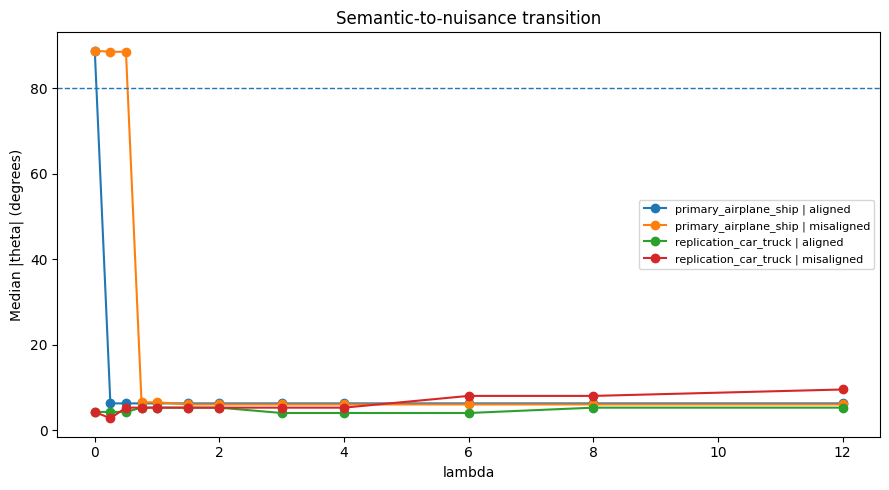

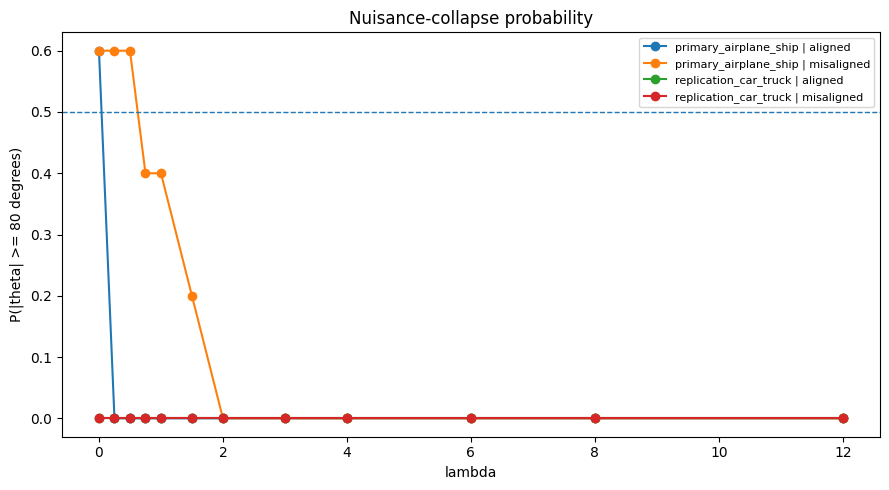

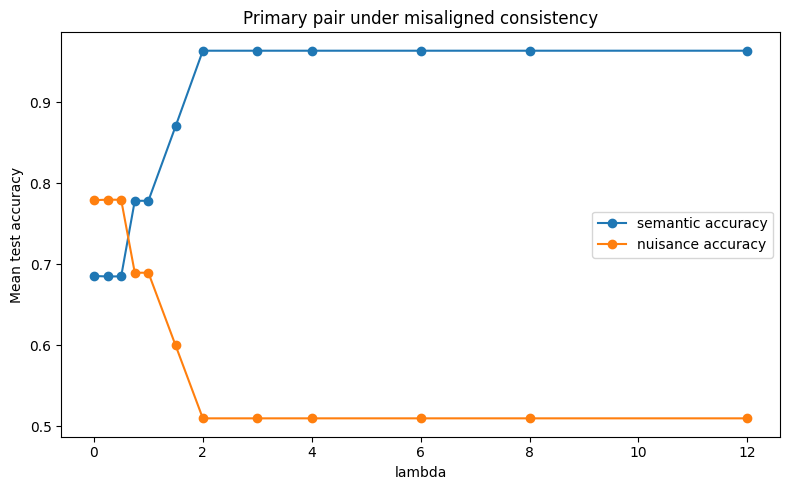

In [15]:
if CALIBRATION_PASSED:
    # 1. Absolute angle: sign-invariant semantic -> nuisance transition
    fig, ax = plt.subplots(figsize=(9, 5))
    for (pair, aug), g in summary.groupby(["pair", "augmentation"]):
        g = g.sort_values("lambda")
        ax.plot(
            g["lambda"],
            g["median_abs_theta_deg"],
            marker="o",
            label=f"{pair} | {aug}"
        )
    ax.axhline(CFG["collapse_angle_deg"], linestyle="--", linewidth=1)
    ax.set_xlabel("lambda")
    ax.set_ylabel("Median |theta| (degrees)")
    ax.set_title("Semantic-to-nuisance transition")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(ROOT / "figure_abs_angle_vs_lambda.png", dpi=200)
    plt.show()

    # 2. Nuisance-collapse probability
    fig, ax = plt.subplots(figsize=(9, 5))
    for (pair, aug), g in summary.groupby(["pair", "augmentation"]):
        g = g.sort_values("lambda")
        ax.plot(
            g["lambda"],
            g["p_nuisance_collapse"],
            marker="o",
            label=f"{pair} | {aug}"
        )
    ax.axhline(0.5, linestyle="--", linewidth=1)
    ax.set_xlabel("lambda")
    ax.set_ylabel("P(|theta| >= 80 degrees)")
    ax.set_title("Nuisance-collapse probability")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(ROOT / "figure_collapse_probability.png", dpi=200)
    plt.show()

    # 3. Primary pair semantic/nuisance accuracy tradeoff
    sub = summary[
        (summary["pair"] == "primary_airplane_ship")
        & (summary["augmentation"] == "misaligned")
    ].sort_values("lambda")

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(
        sub["lambda"],
        sub["mean_test_semantic_acc"],
        marker="o",
        label="semantic accuracy"
    )
    ax.plot(
        sub["lambda"],
        sub["mean_test_nuisance_acc"],
        marker="o",
        label="nuisance accuracy"
    )
    ax.set_xlabel("lambda")
    ax.set_ylabel("Mean test accuracy")
    ax.set_title("Primary pair under misaligned consistency")
    ax.legend()
    fig.tight_layout()
    fig.savefig(ROOT / "figure_primary_accuracy_tradeoff.png", dpi=200)
    plt.show()

## 15. Export all outputs

In [16]:
zip_path = Path("/kaggle/working/STL10_real_image_bridge_final_outputs.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in ROOT.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(ROOT))

print("Final output ZIP:", zip_path)
print("Saved files:")
for p in sorted(ROOT.iterdir()):
    print(" -", p.name)

Final output ZIP: /kaggle/working/STL10_real_image_bridge_final_outputs.zip
Saved files:
 - calibration_training_only.csv
 - chosen_mu.json
 - config.json
 - figure_abs_angle_vs_lambda.png
 - figure_collapse_probability.png
 - figure_primary_accuracy_tradeoff.png
 - run_manifest.json
 - seed_level_results.csv
 - summary.csv
 - theta_curves.csv
 - verdict.json
 - verdict_checks.csv


FINAL EXPERIMENT OUTPUT REVIEW

[1] TRAINING-ONLY CALIBRATION


,mu,M_sem,M_nui,ratio,sem_train_acc,nui_train_acc,nuisance_probe_internal_val_acc,raw_axis_cosine,nuisance_residual_norm_fraction,eligible,failure_reasons
0,0.04,0.785110,0.628227,0.800177,0.968,0.702,0.680,0.050585,0.998720,False,nuisance_probe
1,0.08,0.785620,0.693150,0.882297,0.968,0.852,0.900,0.055000,0.998486,True,NaN
2,0.12,0.776267,0.758254,0.976795,0.970,0.936,0.960,0.064971,0.997887,True,NaN
3,0.16,0.771620,0.819591,1.062170,0.972,0.976,0.996,0.077098,0.997024,False,M_sem<=M_nui|ratio
4,0.20,0.758532,0.865129,1.140530,0.970,0.986,0.996,0.089426,0.995993,False,M_sem<=M_nui|ratio
5,0.24,0.748499,0.891666,1.191273,0.964,0.996,0.996,0.103300,0.994650,False,M_sem<=M_nui|ratio



[2] CHOSEN MU
{
  "chosen_mu": 0.12,
  "calibration_passed": true
}

[3] SEED-LEVEL RESULTS
Rows: 240


,pair,augmentation,seed,mu,lambda,theta_deg,abs_theta_deg,collapse_80deg,objective_L,distortion_D,...,train_nuisance_ari,test_semantic_acc,test_nuisance_acc,test_semantic_ari,test_nuisance_ari,R_sem_endpoint,R_nui_endpoint,empirical_asymmetry_ok,raw_axis_cosine,nuisance_residual_norm_fraction
0,primary_airplane_ship,misaligned,11,0.12,0.00,-7.50,7.50,0.0,0.220584,0.220584,...,-0.000858,0.958125,0.516875,0.839414,0.000514,0.02525,0.03325,False,0.082314,0.996606
1,primary_airplane_ship,misaligned,11,0.12,0.25,-7.50,7.50,0.0,0.225834,0.220584,...,-0.000858,0.958125,0.516875,0.839414,0.000514,0.02525,0.03325,False,0.082314,0.996606
2,primary_airplane_ship,misaligned,11,0.12,0.50,-7.25,7.25,0.0,0.231055,0.220680,...,-0.000858,0.958750,0.516250,0.841707,0.000431,0.02525,0.03325,False,0.082314,0.996606
3,primary_airplane_ship,misaligned,11,0.12,0.75,-6.50,6.50,0.0,0.236209,0.221022,...,-0.000938,0.961250,0.513750,0.850913,0.000131,0.02525,0.03325,False,0.082314,0.996606
4,primary_airplane_ship,misaligned,11,0.12,1.00,-6.50,6.50,0.0,0.241272,0.221022,...,-0.000938,0.961250,0.513750,0.850913,0.000131,0.02525,0.03325,False,0.082314,0.996606
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,replication_car_truck,aligned,55,0.12,3.00,4.00,4.00,0.0,0.240668,0.160418,...,-0.000746,0.972500,0.502500,0.892958,-0.000601,0.03225,0.20550,True,-0.033594,0.999436
236,replication_car_truck,aligned,55,0.12,4.00,4.00,4.00,0.0,0.267418,0.160418,...,-0.000746,0.972500,0.502500,0.892958,-0.000601,0.03225,0.20550,True,-0.033594,0.999436
237,replication_car_truck,aligned,55,0.12,6.00,4.00,4.00,0.0,0.320918,0.160418,...,-0.000746,0.972500,0.502500,0.892958,-0.000601,0.03225,0.20550,True,-0.033594,0.999436
238,replication_car_truck,aligned,55,0.12,8.00,4.00,4.00,0.0,0.374418,0.160418,...,-0.000746,0.972500,0.502500,0.892958,-0.000601,0.03225,0.20550,True,-0.033594,0.999436



[4] AGGREGATE SUMMARY


,pair,augmentation,lambda,median_theta_deg,median_abs_theta_deg,mean_abs_theta_deg,p_nuisance_collapse,mean_test_semantic_acc,std_test_semantic_acc,mean_test_nuisance_acc,std_test_nuisance_acc,mean_test_semantic_ari,mean_test_nuisance_ari,mean_train_agreement,mean_R_sem,mean_R_nui,asymmetry_pass_rate,mean_abs_raw_axis_cosine,mean_nuisance_residual_fraction,n_seeds
0,primary_airplane_ship,aligned,0.00,-88.75,88.75,56.10,0.6,0.685500,0.249729,0.779000,0.242449,0.336792,0.499153,0.86075,0.04365,0.20475,1.0,0.042379,0.998654,5
1,primary_airplane_ship,aligned,0.25,-6.25,6.25,6.85,0.0,0.960375,0.003081,0.513125,0.005502,0.847716,0.000161,0.96255,0.04365,0.20475,1.0,0.042379,0.998654,5
2,primary_airplane_ship,aligned,0.50,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
3,primary_airplane_ship,aligned,0.75,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
4,primary_airplane_ship,aligned,1.00,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
5,primary_airplane_ship,aligned,1.50,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
6,primary_airplane_ship,aligned,2.00,-6.25,6.25,6.80,0.0,0.960500,0.002911,0.513000,0.005366,0.848173,0.000143,0.96265,0.04365,0.20475,1.0,0.042379,0.998654,5
7,primary_airplane_ship,aligned,3.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5
8,primary_airplane_ship,aligned,4.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5
9,primary_airplane_ship,aligned,6.00,-6.25,6.25,6.80,0.0,0.962125,0.003081,0.511625,0.004772,0.854177,-0.000011,0.96330,0.04365,0.20475,1.0,0.042379,0.998654,5



[5] VERDICT CHECKS


,pair,baseline_ok,misaligned_asymmetry_ok,aligned_asymmetry_ok,angle_moves_toward_nuisance,semantic_accuracy_decreases,nuisance_accuracy_increases,misaligned_collapse_at_max_lambda,aligned_control_safe_all_lambda,median_abs_angle_monotone,first_lambda_pcollapse_ge_0_5,pair_go
0,primary_airplane_ship,False,False,True,False,False,False,False,False,False,0.0,False
1,replication_car_truck,True,False,True,True,True,True,False,True,False,NaN,False



[6] FINAL VERDICT
{
  "experiment_id": "STL10_real_image_controlled_nuisance_audited_v2",
  "calibration_passed": true,
  "chosen_mu": 0.12,
  "go": false,
  "checks": [
    {
      "pair": "primary_airplane_ship",
      "baseline_ok": false,
      "misaligned_asymmetry_ok": false,
      "aligned_asymmetry_ok": true,
      "angle_moves_toward_nuisance": false,
      "semantic_accuracy_decreases": false,
      "nuisance_accuracy_increases": false,
      "misaligned_collapse_at_max_lambda": false,
      "aligned_control_safe_all_lambda": false,
      "median_abs_angle_monotone": false,
      "first_lambda_pcollapse_ge_0_5": 0.0,
      "pair_go": false
    },
    {
      "pair": "replication_car_truck",
      "baseline_ok": true,
      "misaligned_asymmetry_ok": false,
      "aligned_asymmetry_ok": true,
      "angle_moves_toward_nuisance": true,
      "semantic_accuracy_decreases": true,
      "nuisance_accuracy_increases": true,
      "misaligned_collapse_at_max_lambda": false,
      "

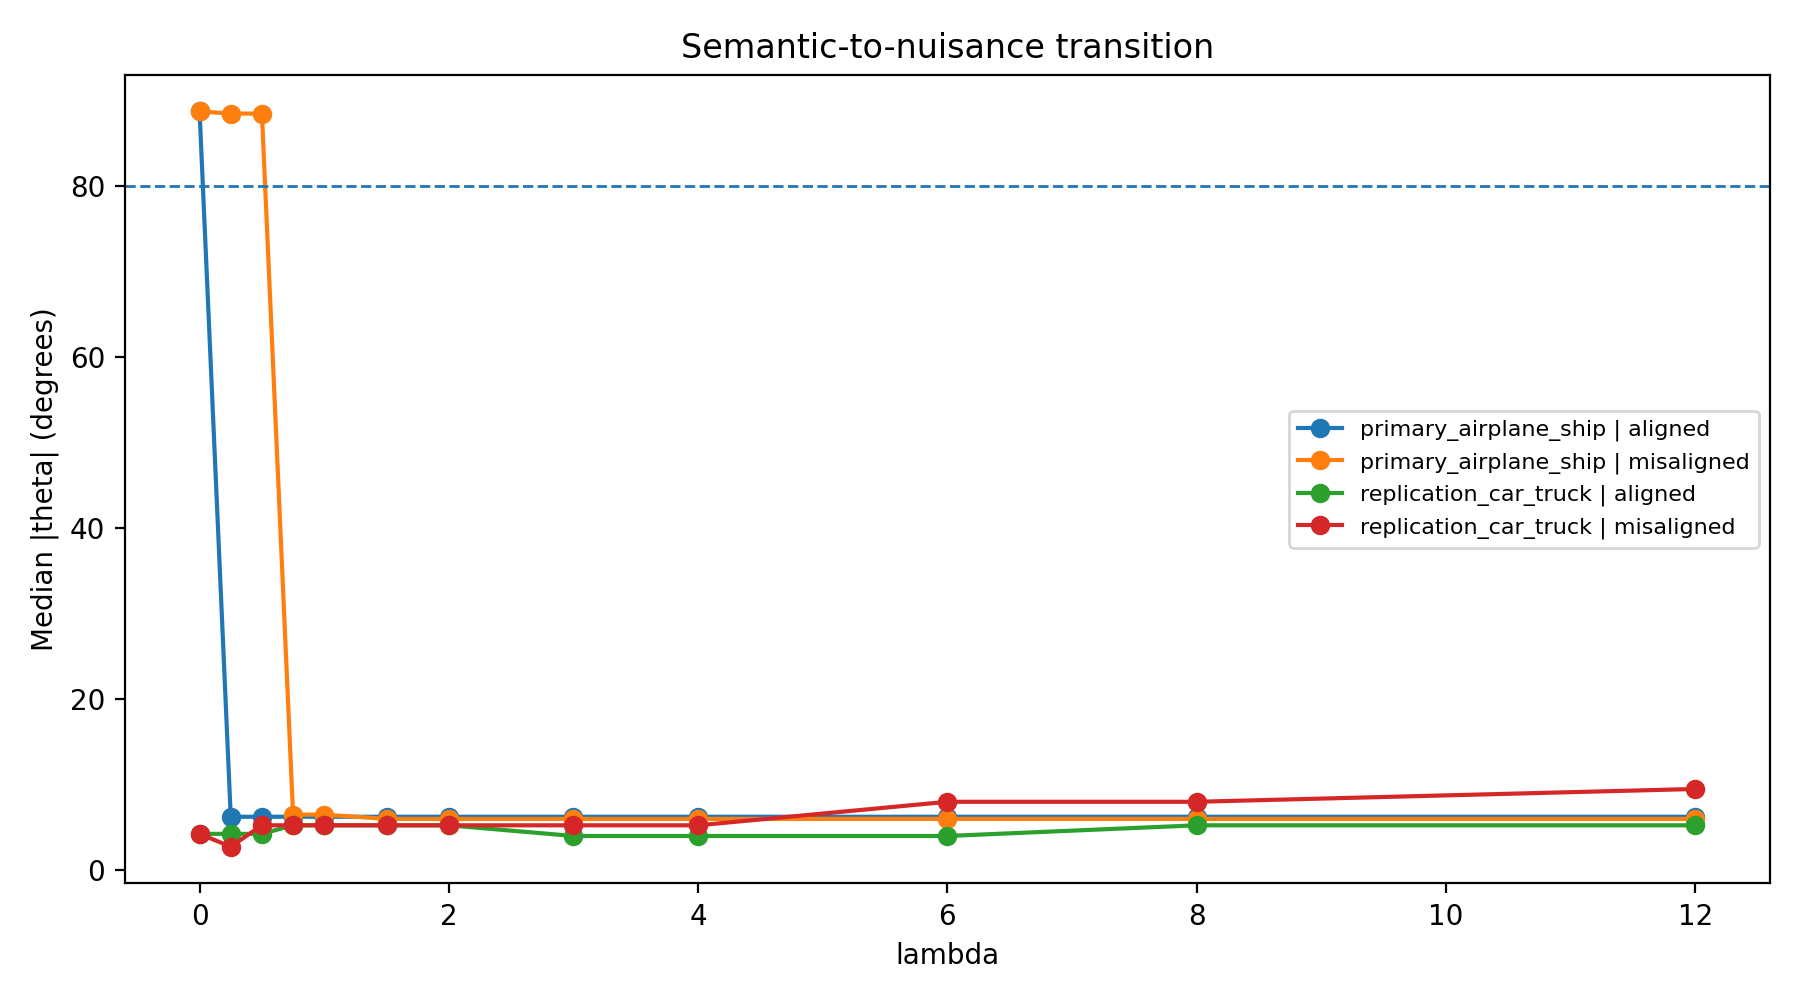


figure_collapse_probability.png


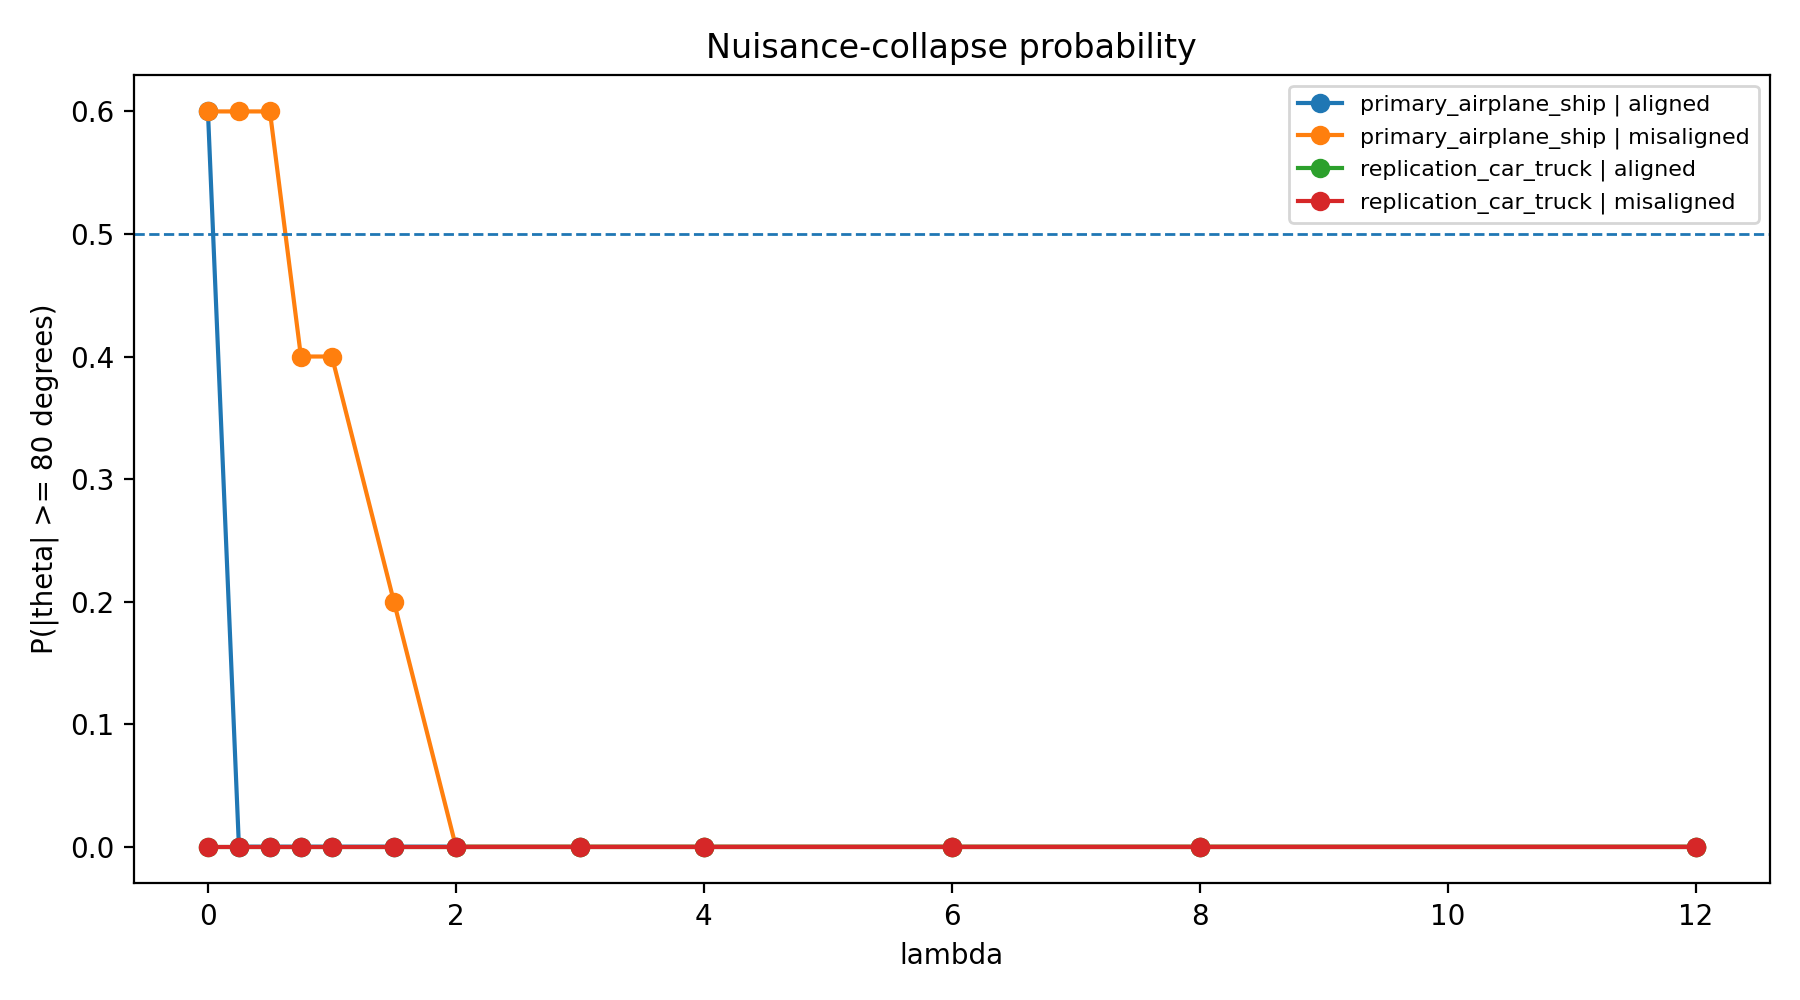


figure_primary_accuracy_tradeoff.png


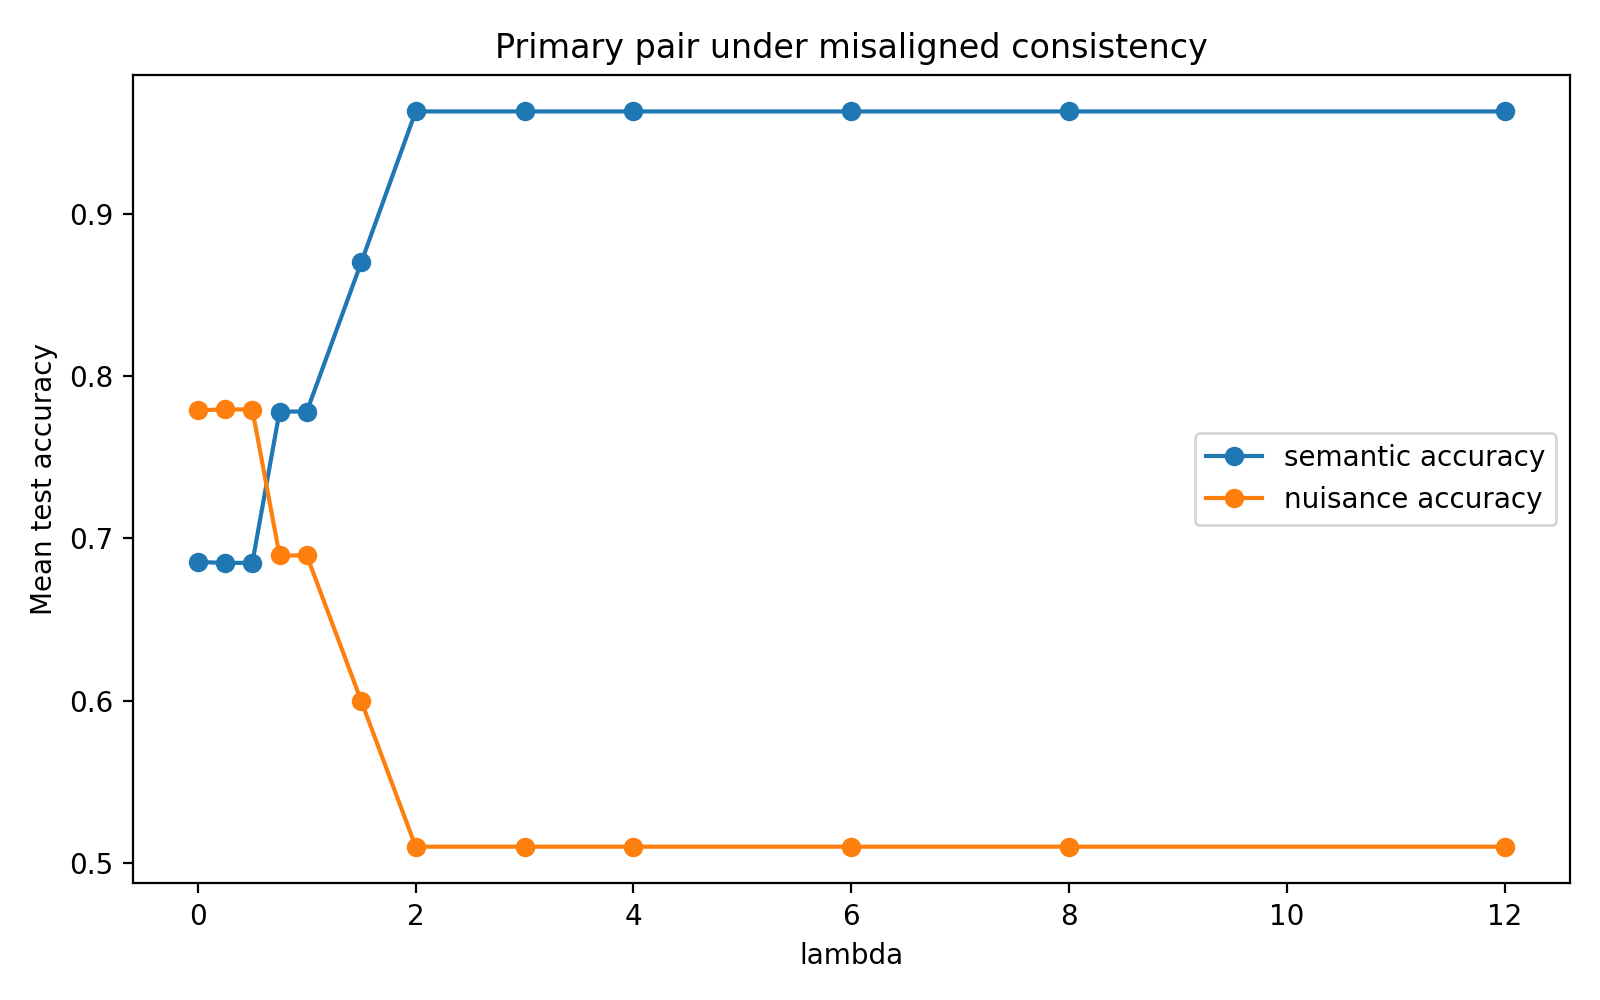


[9] ALL SAVED OUTPUT FILES
calibration_training_only.csv                       0.94 KB
chosen_mu.json                                      0.05 KB
config.json                                         8.43 KB
figure_abs_angle_vs_lambda.png                     87.82 KB
figure_collapse_probability.png                    87.65 KB
figure_primary_accuracy_tradeoff.png               70.95 KB
run_manifest.json                                  10.63 KB
seed_level_results.csv                             69.97 KB
summary.csv                                        12.09 KB
theta_curves.csv                                 1622.40 KB
verdict.json                                        1.24 KB
verdict_checks.csv                                  0.43 KB

[10] ZIP STATUS
ZIP created successfully.
Path: /kaggle/working/STL10_real_image_bridge_final_outputs.zip
Size: 0.71 MB

END OF EXPERIMENT REVIEW


In [17]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image as IPyImage

print("=" * 80)
print("FINAL EXPERIMENT OUTPUT REVIEW")
print("=" * 80)

# ------------------------------------------------------------------
# 1. Calibration
# ------------------------------------------------------------------
cal_path = ROOT / "calibration_training_only.csv"
if cal_path.exists():
    print("\n[1] TRAINING-ONLY CALIBRATION")
    cal_display = pd.read_csv(cal_path)
    display(cal_display)
else:
    print("\n[1] Calibration file not found.")

# ------------------------------------------------------------------
# 2. Chosen nuisance strength
# ------------------------------------------------------------------
chosen_mu_path = ROOT / "chosen_mu.json"
if chosen_mu_path.exists():
    print("\n[2] CHOSEN MU")
    with open(chosen_mu_path, "r") as f:
        chosen_mu_info = json.load(f)
    print(json.dumps(chosen_mu_info, indent=2))
else:
    print("\n[2] chosen_mu.json not found.")

# ------------------------------------------------------------------
# 3. Seed-level results
# ------------------------------------------------------------------
seed_path = ROOT / "seed_level_results.csv"
if seed_path.exists():
    print("\n[3] SEED-LEVEL RESULTS")
    seed_df = pd.read_csv(seed_path)
    print("Rows:", len(seed_df))
    display(seed_df)
else:
    print("\n[3] Seed-level results not available.")

# ------------------------------------------------------------------
# 4. Aggregate summary
# ------------------------------------------------------------------
summary_path = ROOT / "summary.csv"
if summary_path.exists():
    print("\n[4] AGGREGATE SUMMARY")
    summary_df = pd.read_csv(summary_path)
    display(summary_df)
else:
    print("\n[4] Summary not available.")

# ------------------------------------------------------------------
# 5. GO / NO-GO checks
# ------------------------------------------------------------------
checks_path = ROOT / "verdict_checks.csv"
if checks_path.exists():
    print("\n[5] VERDICT CHECKS")
    checks_df = pd.read_csv(checks_path)
    display(checks_df)
else:
    print("\n[5] Verdict checks not available.")

# ------------------------------------------------------------------
# 6. Final verdict
# ------------------------------------------------------------------
verdict_path = ROOT / "verdict.json"
if verdict_path.exists():
    print("\n[6] FINAL VERDICT")
    with open(verdict_path, "r") as f:
        verdict_info = json.load(f)
    print(json.dumps(verdict_info, indent=2))
else:
    print("\n[6] Verdict file not found.")

# ------------------------------------------------------------------
# 7. Provenance / run manifest
# ------------------------------------------------------------------
manifest_path = ROOT / "run_manifest.json"
if manifest_path.exists():
    print("\n[7] RUN MANIFEST / PROVENANCE")
    with open(manifest_path, "r") as f:
        manifest_info = json.load(f)

    # Print the most useful fields without flooding the notebook
    useful_manifest = {
        "experiment_id": manifest_info.get("experiment_id"),
        "python": manifest_info.get("python"),
        "torch": manifest_info.get("torch"),
        "torchvision": manifest_info.get("torchvision"),
        "sklearn": manifest_info.get("sklearn"),
        "cuda_available": manifest_info.get("cuda_available"),
        "cuda_version": manifest_info.get("cuda_version"),
        "gpu": manifest_info.get("gpu"),
        "stl_root": manifest_info.get("stl_root"),
        "stl_md5": manifest_info.get("stl_md5"),
    }

    print(json.dumps(useful_manifest, indent=2))
else:
    print("\n[7] Run manifest not found.")

# ------------------------------------------------------------------
# 8. Key figures
# ------------------------------------------------------------------
print("\n[8] FIGURES")

figure_files = [
    ROOT / "figure_abs_angle_vs_lambda.png",
    ROOT / "figure_collapse_probability.png",
    ROOT / "figure_primary_accuracy_tradeoff.png",
]

found_fig = False

for fig_path in figure_files:
    if fig_path.exists():
        found_fig = True
        print(f"\n{fig_path.name}")
        display(IPyImage(filename=str(fig_path)))

if not found_fig:
    print("No figure files found.")

# ------------------------------------------------------------------
# 9. Output files list
# ------------------------------------------------------------------
print("\n[9] ALL SAVED OUTPUT FILES")

if ROOT.exists():
    for p in sorted(ROOT.iterdir()):
        if p.is_file():
            size_kb = p.stat().st_size / 1024
            print(f"{p.name:45s} {size_kb:10.2f} KB")
else:
    print("Output directory does not exist.")

# ------------------------------------------------------------------
# 10. ZIP confirmation
# ------------------------------------------------------------------
zip_path = Path("/kaggle/working/STL10_real_image_bridge_final_outputs.zip")

print("\n[10] ZIP STATUS")

if zip_path.exists():
    size_mb = zip_path.stat().st_size / (1024 ** 2)
    print("ZIP created successfully.")
    print("Path:", zip_path)
    print(f"Size: {size_mb:.2f} MB")
else:
    print("ZIP file was not created.")

print("\n" + "=" * 80)
print("END OF EXPERIMENT REVIEW")
print("=" * 80)